In [1]:
import pandas as pd

df = pd.read_csv('sales_data.csv')
df.shape

(1030, 14)

In [2]:
df.head()

,order_date,shipping_date,delivery_date,region,category,product_id,quantity,unit_price,customer_id,customer_age,customer_gender,satisfaction,status,total_sales
0,2023-01-01,2023-01-04,2023-01-03,부산,전자제품,2772,61,34977.69,327,67.0,M,1.0,배송중,2133639.09
1,2023-01-02,2023-01-06,2023-01-04,부산,식품,3780,64,312589.27,318,34.0,M,4.0,배송완료,20005713.28
2,2023-01-03,2023-01-04,2023-01-05,부산,의류,8423,5,111813.88,297,50.0,F,4.0,배송완료,559069.40
3,2023-01-04,2023-01-07,2023-01-10,대구,식품,3871,53,297971.54,479,61.0,M,5.0,배송완료,15792491.62
4,2023-01-05,2023-01-08,2023-01-10,서울,식품,1660,55,65058.60,499,60.0,F,2.0,배송중,3578223.00


In [3]:
import matplotlib.pyplot as plt
import platform

c:\Users\dkswj\Desktop\강의자료\웹 기반 시스템\flask-practice1\data_analysis\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 49688 (\N{HANGUL SYLLABLE SU}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
c:\Users\dkswj\Desktop\강의자료\웹 기반 시스템\flask-practice1\data_analysis\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 47049 (\N{HANGUL SYLLABLE RYANG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


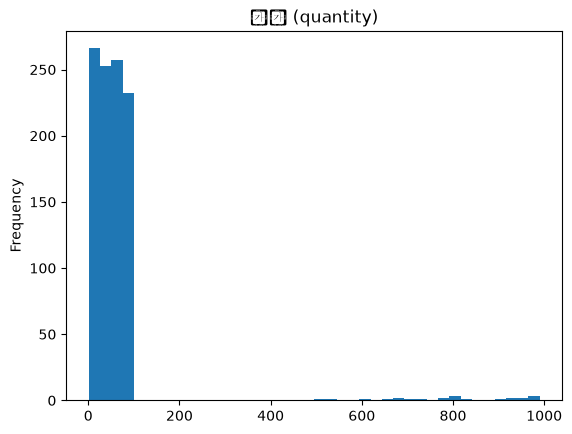

In [4]:
df['quantity'].plot.hist(bins=40,title='수량 (quantity)')
plt.show()

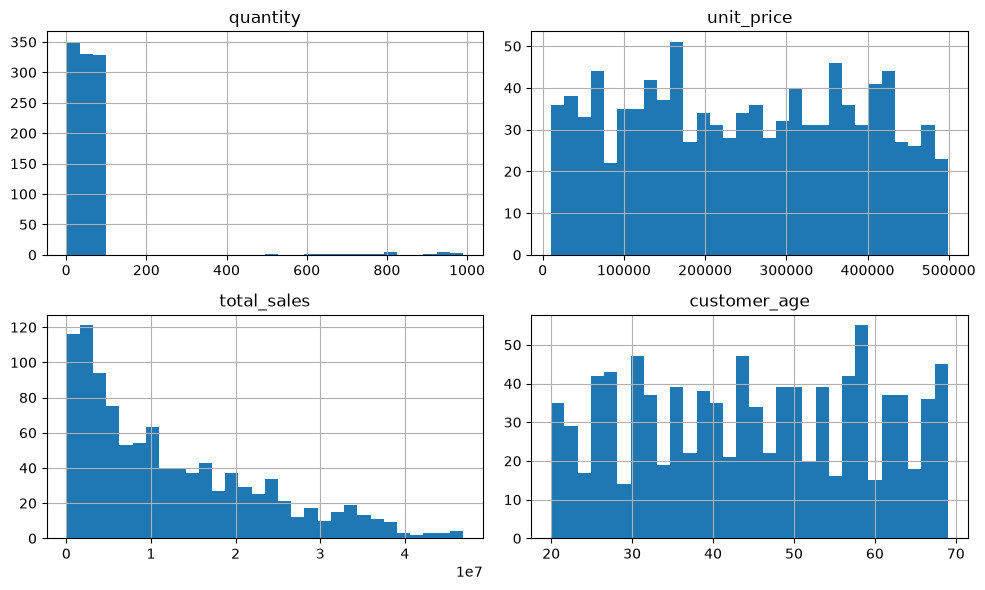

In [5]:
cols = ["quantity", "unit_price",
"total_sales", "customer_age"]
df[cols].hist(bins=30, figsize=(10, 6))
plt.tight_layout()
plt.show()

In [6]:
dropped = df.dropna(subset=["customer_age"])
print(len(df), "->", len(dropped))

1030 -> 979


In [7]:
age_mean = df["customer_age"].fillna(df["customer_age"].mean())
print("평균 :", round(age_mean.mean(), 3))
print("중앙값:", round(age_mean.median(), 3))
print("최빈값:", round(age_mean.mode()[0], 3))

평균 : 44.858
중앙값: 44.858
최빈값: 44.858


In [8]:
# 결정 : 세 칸의 빈칸은 그대로 둔다
print(df["customer_age"].count(), "/", len(df))

979 / 1030


In [9]:
before = len(df)
df = df.drop_duplicates()
print(before, "->", len(df))

1030 -> 1004


In [13]:
Q1 = df["quantity"].quantile(0.25)
Q3 = df["quantity"].quantile(0.75)
IQR = Q3 - Q1
print("Q1 =", Q1, " Q3 =", Q3, " IQR =", IQR)
print("수염 끝(상한) =", Q3 + 1.5 * IQR)

Q1 = 25.0  Q3 = 75.0  IQR = 50.0
수염 끝(상한) = 150.0


In [14]:
by_iqr = df["quantity"] > Q3 + 1.5 * IQR # 통계 규칙 : 26쪽 상한 150 밖
by_rule = df["quantity"] > 100 # 업무 규칙 : 한 주문 100개 넘지 않는다
print("IQR 규칙 :", by_iqr.sum(), " 업무 규칙 :", by_rule.sum(), " 둘이 같은 줄인가 :", (by_iqr == by_rule).all())

IQR 규칙 : 22  업무 규칙 : 22  둘이 같은 줄인가 : True


In [15]:
bad = by_rule
calc = df["quantity"] * df["unit_price"]
diff = (df["total_sales"] - calc).abs()
print("22건 중 금액이 안 맞는 줄 :", (diff[bad] > 1).sum())
ratio = df["total_sales"] / df["unit_price"]
ratio[bad].round(2).head(6)

22건 중 금액이 안 맞는 줄 : 22


31     95.0
188    63.0
273    77.0
316    52.0
334    18.0
361    82.0
dtype: float64

In [16]:
df.loc[bad, "quantity"] = ratio[bad].round().astype(int)
calc = df["quantity"] * df["unit_price"]
diff = (df["total_sales"] - calc).abs()
print("수량 최대 :", df["quantity"].max(), " 불일치 :", (diff > 1).sum())

수량 최대 : 99  불일치 : 0


In [17]:
df["date_error"] = df["delivery_date"] < df["shipping_date"]
df["date_error"].value_counts()

date_error
False    857
True     147
Name: count, dtype: int64

In [18]:
df.to_csv("sales_clean.csv", index=False)
df.shape

(1004, 15)

In [19]:
df[["quantity", "unit_price", "total_sales", "customer_age"]].agg(["mean", "median", "skew"]).round(2)

,quantity,unit_price,total_sales,customer_age
mean,49.41,250146.14,12413727.16,44.90
median,48.00,249449.48,9425457.90,45.00
skew,0.04,0.00,0.94,-0.02
